# desilike test on the Full sample (exploratory, not part of the pipeline)

**Question.** Does desilike, DESI's official BAO fitter, reproduce `run_all` when it gets **our**
monopole, **our** covariance and the same settings? If yes, we can switch the *fitting* to
desilike; monopoles, covariances and errors stay ours.

**What desilike does here:** the BAO template (linear P(k) and its no-wiggle version), the model
ξ(s; α, Σ) + broadband, the likelihood and the fit (Minuit).
**What we give it:** ξ₀(s) of Full, the `run_all` covariance (`gaussian_cov_pk`), the cosmology
(COSMO of `src/bao_fitting.py`: MultiDark-Planck), fit range 65–135, Σ ~ N(Σ_theory, 2) with Σ_theory = 7.78, broadband a₀ + a₁/s + a₂/s².

Sections: 1 our inputs · 2 template P(k) · 3 template ξ(s) · 4 what α and Σ do · 5 BAO fit ·
6 detection Δχ² · 7 χ²(α) profile · 8 summary.

Colours: **blue = ours** (`bao_fitting` / `run_all`), **orange = desilike**, black points = data.
Nothing is written to disk.

In [2]:
import os, sys, warnings
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

REPO = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))   # notebook lives in notebooks/exploratory
sys.path.insert(0, os.path.join(REPO, 'src'))
import bao_fitting as bf

from cosmoprimo.fiducial import Cosmology
from desilike.theories.galaxy_clustering import (BAOPowerSpectrumTemplate,
                                                 DampedBAOWigglesTracerCorrelationFunctionMultipoles)
from desilike.observables.galaxy_clustering import TracerCorrelationFunctionMultipolesObservable
from desilike.likelihoods import ObservablesGaussianLikelihood
from desilike.profilers import MinuitProfiler

OURS, DESI, DATA = '#2a78d6', '#eb6834', '0.15'
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25, 'lines.linewidth': 1.6})

# ---- settings (as run_all, notebook final/bao_fitting.ipynb, run 1) ----
monopole_file = os.path.join(REPO, 'data/processed/monopoles/box/mag=-21.2_sep=5.0-150.0_binsep=5.0_full.npz')
pk_file = os.path.join(REPO, 'data/processed/pk/box/pk_XISMU_box_mag-21.2_dist_fil.npz')
spec_key = 'full'                       # label of this sample in the spectra file
fit_range = (65., 135.)

# Cosmology: ONE source of truth, COSMO in src/bao_fitting.py (MultiDark-Planck); desilike gets the same
C0 = bf.COSMO
cosmo = Cosmology(h=C0['H0'] / 100., omega_b=C0['ombh2'], omega_cdm=C0['omch2'], A_s=C0['As'], n_s=C0['ns'],
                  m_ncdm=[] if C0.get('mnu', 0.06) == 0 else [C0['mnu']], engine='camb')
lin = bf.linear_theory()
Sigma_mean, Sigma_sd = bf.sigma_nl_theory(lin)['Sigma_mono'], 2.   # run_all's Sigma prior: N(theory, 2)
print(f"COSMO = {C0}")
print(f"Sigma prior: N({Sigma_mean:.2f}, {Sigma_sd})")

COSMO = {'H0': 67.77, 'ombh2': 0.02214, 'omch2': 0.118911, 'mnu': 0.0, 'As': 2.1186e-09, 'ns': 0.96}
Sigma prior: N(7.78, 2.0)


## 1. Our inputs: the monopole and the `run_all` covariance

Exactly what `run_all` uses: b from 40–70 h⁻¹Mpc (only for the low-k part of the covariance),
then `gaussian_cov_pk` from the measured spectra. Left: s²ξ₀ with √diag(C) errors, fit range
shaded. Right: correlation matrix C_ij/√(C_ii C_jj) in the fit range; neighbouring bins are
strongly correlated, which is why the eye over-reads bumps.

N = 2400560,  b (covariance only) = 1.032,  14 bins in (65.0, 135.0)


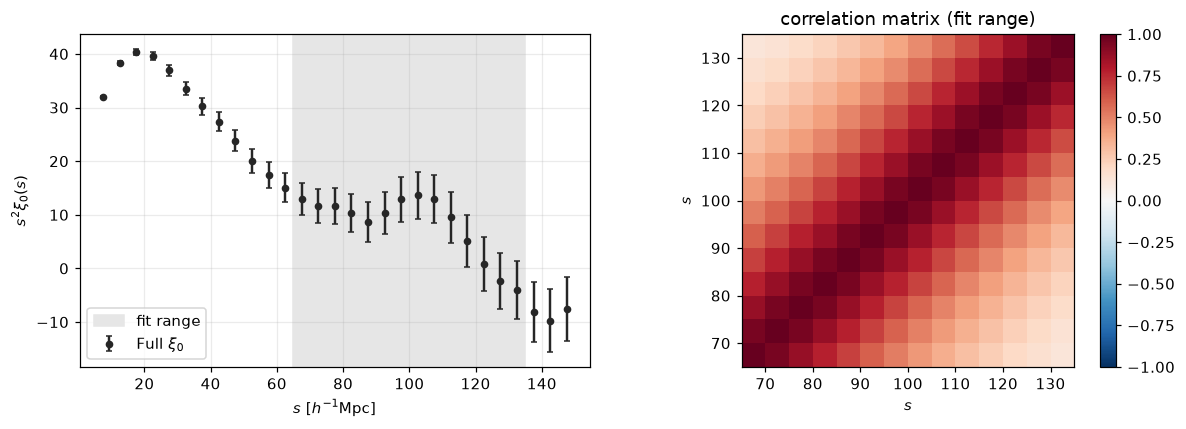

In [3]:
k_ours, Pw_ours, Pnw_ours = bf.generate_templates(lin=lin)
T = bf.BAOTemplate(k_ours, Pw_ours, Pnw_ours, lin)

s, xi, n_gal = bf.load_monopole(monopole_file)
edges = bf.edges_from_centres(s)
spec = bf.load_spectra(pk_file)
bias = bf.estimate_bias_independent(s, xi, edges, n_gal / bf.L_BOX**3, T)
C = bf.gaussian_cov_pk(edges, spec, [spec['labels'].index(spec_key)], [bias['b']], lin)
sig = np.sqrt(np.diag(C))
m = (s >= fit_range[0]) & (s <= fit_range[1])
print(f"N = {n_gal},  b (covariance only) = {bias['b']:.3f},  {m.sum()} bins in {fit_range}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.axvspan(*fit_range, color='0.9', zorder=0, label='fit range')
a1.errorbar(s, s**2 * xi, yerr=s**2 * sig, fmt='o', ms=4, color=DATA, capsize=2, label=r'Full $\xi_0$')
a1.set_xlabel(r'$s\ [h^{-1}{\rm Mpc}]$'); a1.set_ylabel(r'$s^2\xi_0(s)$'); a1.legend()
corr = C[np.ix_(m, m)] / np.outer(sig[m], sig[m])
im = a2.imshow(corr, origin='lower', cmap='RdBu_r', vmin=-1, vmax=1,
               extent=[s[m][0] - 2.5, s[m][-1] + 2.5, s[m][0] - 2.5, s[m][-1] + 2.5])
a2.set_xlabel(r'$s$'); a2.set_ylabel(r'$s$'); a2.set_title('correlation matrix (fit range)')
a2.grid(False); fig.colorbar(im, ax=a2); fig.tight_layout(); plt.show()

## 2. The template in Fourier space: P_lin(k) and its no-wiggle version

desilike computes the linear P(k) with CAMB (through cosmoprimo) for the cosmology we give it,
and removes the BAO with the Wallisch (2018) method (`with_now='wallish2018'`, cosmoprimo's
spelling), the same *method* as ours but a different *implementation*.

* Top: P_lin and P_nw, both codes.
* Middle: the wiggles, P_lin/P_nw − 1. This is all the BAO information the fit uses.
* Bottom: ratio of the two codes' P_nw. A difference here changes the **no-wiggle** model and so
  the detection Δχ² (section 6), even when the BAO fits agree.

r_d: desilike 100.07, ours 100.07 h^-1 Mpc;  f: desilike 0.520, ours 0.520 (f is set to 0 below: real space)


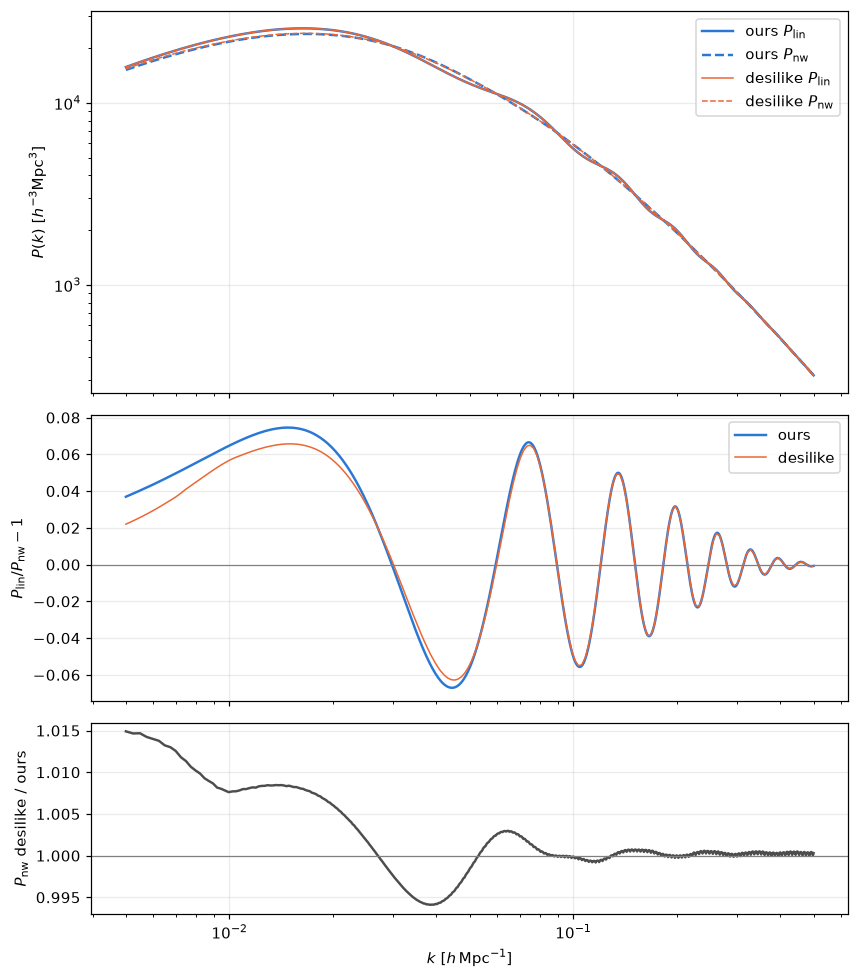

In [4]:
template = BAOPowerSpectrumTemplate(z=0., fiducial=cosmo, apmode='qiso', with_now='wallish2018')
template()                                   # compute at the fiducial point (qiso = 1)
k_d, Plin_d, Pnw_d = template.k, template.pk_dd, template.pknow_dd
print(f"r_d: desilike {template.fiducial.rs_drag:.2f}, ours {lin['rd']:.2f} h^-1 Mpc;  "
      f"f: desilike {template.f:.3f}, ours {lin['f']:.3f} (f is set to 0 below: real space)")

kk = np.linspace(0.005, 0.5, 2000)
Pl_o = np.interp(kk, k_ours, Pw_ours); Pn_o = np.interp(kk, k_ours, Pnw_ours)
Pl_d = np.interp(kk, k_d, Plin_d);     Pn_d = np.interp(kk, k_d, Pnw_d)

fig, ax = plt.subplots(3, 1, figsize=(8, 9), sharex=True, gridspec_kw=dict(height_ratios=(2, 1.5, 1)))
ax[0].loglog(kk, Pl_o, color=OURS, label=r'ours $P_{\rm lin}$')
ax[0].loglog(kk, Pn_o, color=OURS, ls='--', label=r'ours $P_{\rm nw}$')
ax[0].loglog(kk, Pl_d, color=DESI, lw=1, label=r'desilike $P_{\rm lin}$')
ax[0].loglog(kk, Pn_d, color=DESI, lw=1, ls='--', label=r'desilike $P_{\rm nw}$')
ax[0].set_ylabel(r'$P(k)\ [h^{-3}{\rm Mpc}^3]$'); ax[0].legend()
ax[1].plot(kk, Pl_o / Pn_o - 1, color=OURS, label='ours')
ax[1].plot(kk, Pl_d / Pn_d - 1, color=DESI, lw=1, label='desilike')
ax[1].axhline(0, color='0.5', lw=0.8); ax[1].set_ylabel(r'$P_{\rm lin}/P_{\rm nw}-1$'); ax[1].legend()
ax[2].plot(kk, Pn_d / Pn_o, color='0.3')
ax[2].axhline(1, color='0.5', lw=0.8); ax[2].set_ylabel(r'$P_{\rm nw}$ desilike / ours')
ax[2].set_xlabel(r'$k\ [h\,{\rm Mpc}^{-1}]$'); ax[2].set_xscale('log')
fig.tight_layout(); plt.show()

## 3. The template in configuration space: ξ(s)

The same two spectra Fourier-transformed to ξ(s), undamped (Σ = 0) and damped (Σ = Σ_theory), with
b = 1, α = 1 and no broadband. Ours: `BAOTemplate`. desilike: its model with all nuisance terms
off, evaluated on a fine s grid (no bin averaging here).

Left: s²ξ for BAO and no-wiggle. Right: the BAO part alone, s²(ξ − ξ_nw).

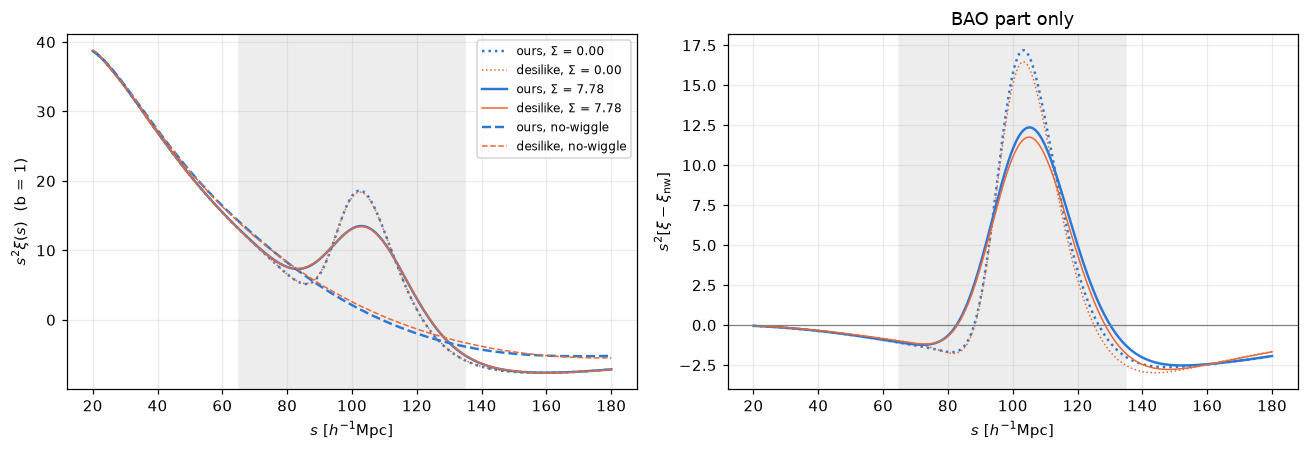

In [5]:
s_fine = np.linspace(20., 180., 321)

def desilike_xi(qiso=1., Sigma=Sigma_mean, only_now=False, s_eval=s_fine):
    # desilike model xi_0 with b1 = 1, f = 0, no FoG, no broadband
    tpl = BAOPowerSpectrumTemplate(z=0., fiducial=cosmo, apmode='qiso', with_now='wallish2018', only_now=only_now)
    th = DampedBAOWigglesTracerCorrelationFunctionMultipoles(ells=(0,), template=tpl, broadband='power', s=s_eval)
    P = th.init.params
    P['dbeta'].update(value=0., fixed=True); P['sigmas'].update(value=0., fixed=True)
    P['sigmapar'].update(derived='{sigmaper}')
    zero_bb = {p.name: 0. for p in P if p.name.startswith('al0_')}
    return th(qiso=qiso, b1=1., sigmaper=Sigma, **zero_bb)[0]

xi_d = {S: desilike_xi(Sigma=S) for S in (1e-3, Sigma_mean)}
xi_d_nw = desilike_xi(only_now=True)
xi_o = {S: T.xi(S, s=s_fine) for S in (0., Sigma_mean)}
xi_o_nw = T.xi_nw(s=s_fine)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
for (So, Sd), ls in (((0., 1e-3), ':'), ((Sigma_mean, Sigma_mean), '-')):
    a1.plot(s_fine, s_fine**2 * xi_o[So], color=OURS, ls=ls, label=f'ours, Σ = {So:.2f}')
    a1.plot(s_fine, s_fine**2 * xi_d[Sd], color=DESI, ls=ls, lw=1, label=f'desilike, Σ = {round(Sd, 2):.2f}')
    a2.plot(s_fine, s_fine**2 * (xi_o[So] - xi_o_nw), color=OURS, ls=ls)
    a2.plot(s_fine, s_fine**2 * (xi_d[Sd] - xi_d_nw), color=DESI, ls=ls, lw=1)
a1.plot(s_fine, s_fine**2 * xi_o_nw, color=OURS, ls='--', label='ours, no-wiggle')
a1.plot(s_fine, s_fine**2 * xi_d_nw, color=DESI, ls='--', lw=1, label='desilike, no-wiggle')
for a in (a1, a2):
    a.axvspan(*fit_range, color='0.93', zorder=0); a.set_xlabel(r'$s\ [h^{-1}{\rm Mpc}]$')
a1.set_ylabel(r'$s^2\xi(s)$  (b = 1)'); a1.legend(fontsize=8)
a2.axhline(0, color='0.5', lw=0.8); a2.set_ylabel(r'$s^2[\xi - \xi_{\rm nw}]$'); a2.set_title('BAO part only')
fig.tight_layout(); plt.show()

## 4. What α and Σ do to the model (desilike)

Illustration only. α stretches the BAO feature (α < 1 moves the peak to larger s: the data look
like a universe with a larger sound horizon than the template). Σ smooths it: it lowers and widens
the peak and fills the dip, without moving it. That is why α is robust and Σ is hard to measure
with one box.

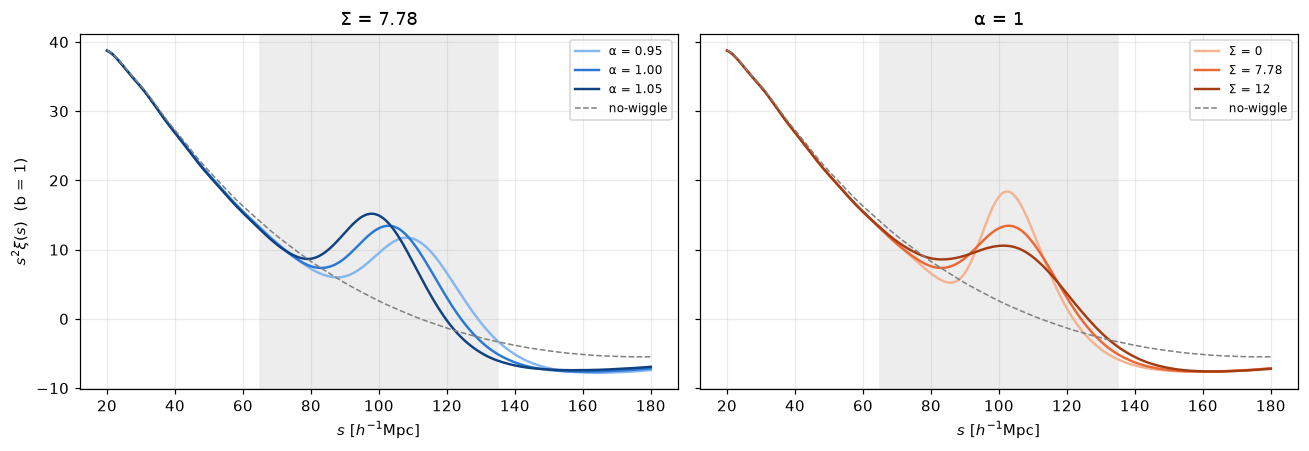

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for q, c in zip((0.95, 1.00, 1.05), ('#86b6ef', '#2a78d6', '#104281')):
    a1.plot(s_fine, s_fine**2 * desilike_xi(qiso=q), color=c, label=f'α = {q:.2f}')
for S, c in zip((1e-3, Sigma_mean, 12.), ('#f4b393', '#eb6834', '#a33c12')):
    a2.plot(s_fine, s_fine**2 * desilike_xi(Sigma=S), color=c, label=f'Σ = {round(S, 2):g}')
a1.set_title(f'Σ = {Sigma_mean:.2f}'); a2.set_title('α = 1')
for a in (a1, a2):
    a.plot(s_fine, s_fine**2 * xi_d_nw, color='0.5', ls='--', lw=1, label='no-wiggle')
    a.axvspan(*fit_range, color='0.93', zorder=0); a.set_xlabel(r'$s\ [h^{-1}{\rm Mpc}]$'); a.legend(fontsize=8)
a1.set_ylabel(r'$s^2\xi(s)$  (b = 1)'); fig.tight_layout(); plt.show()

## 5. The BAO fit with desilike

Model: the desilike BAO model for the monopole with
* `dbeta = 0` → f = 0 (real space, no Kaiser term); `sigmas = 0` → no fingers of god;
* one isotropic damping: `sigmaper` ~ N(Σ_theory, 2), `sigmapar` tied to it;
* broadband `al0_-2, al0_-1, al0_0` = a₂/s² + a₁/s + a₀ (Xu+12, as `run_all`); `al0_1`, `al0_2` off;
* free: `qiso` (= α, flat 0.8–1.2), `b1` (amplitude), Σ, a₀, a₁, a₂.

Data: our ξ₀ and covariance in the fit range. `slim={0: (65, 135, 5)}` gives desilike the real bin
edges, and `wmatrix={'resolution': 10}` makes it **average the model over each bin** (10 sub-points),
as `bao_fitting` and the DD/RR estimator do. Without it the model is evaluated at bin centres
(the BAO fit barely changes, the no-wiggle χ² does).

Fit: `MinuitProfiler` (maximum of the posterior, then the Δχ² = 1 interval of α).
For comparison, the same fit with our code (`bf.fit_bao`, what `run_all` calls).

+-----------------------------------+--------+---------+--------+---------------+
| chi2 / (14 - 6) = 7.17 / 8 = 0.90 | varied | bestfit | error  |   interval    |
+-----------------------------------+--------+---------+--------+---------------+
|               qiso                |  True  |  0.986  | 0.019  | -0.019/+0.020 |
|                b1                 |  True  |  0.89   |  0.14  |               |
|             sigmaper              |  True  |   6.5   |  1.8   |               |
|              al0_-2               |  True  | -1.0e-4 | 2.3e-4 |               |
|              al0_-1               |  True  | 0.0010  | 0.0016 |               |
|               al0_0               |  True  | -0.0019 | 0.0027 |               |
+-----------------------------------+--------+---------+--------+---------------+


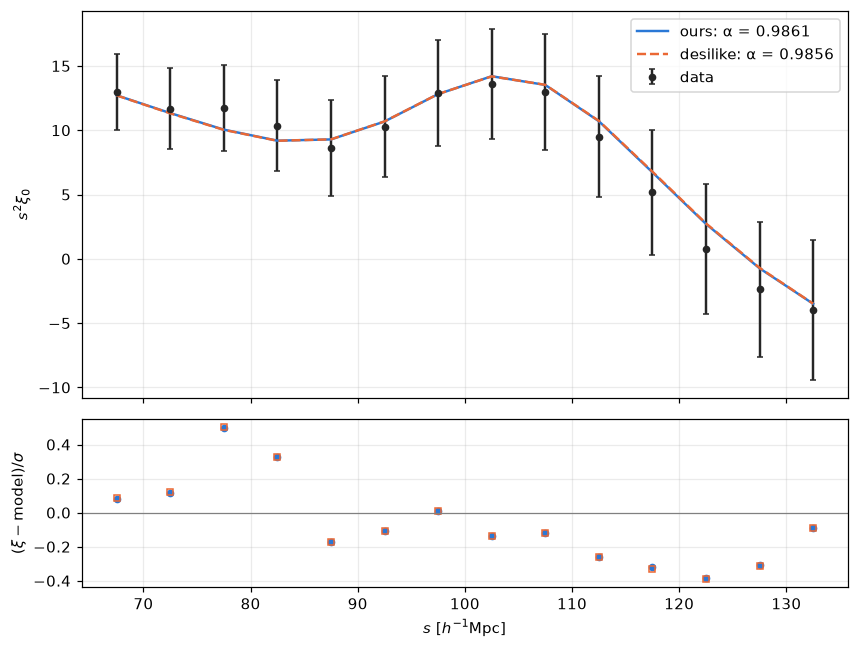

In [7]:
def make_likelihood(only_now=False):
    tpl = BAOPowerSpectrumTemplate(z=0., fiducial=cosmo, apmode='qiso', with_now='wallish2018', only_now=only_now)
    th = DampedBAOWigglesTracerCorrelationFunctionMultipoles(ells=(0,), template=tpl, broadband='power')
    P = th.init.params
    P['dbeta'].update(value=0., fixed=True)
    P['sigmas'].update(value=0., fixed=True)
    P['sigmaper'].update(fixed=False, value=Sigma_mean,
                         prior=dict(dist='norm', loc=Sigma_mean, scale=Sigma_sd, limits=[0., 30.]))
    P['sigmapar'].update(derived='{sigmaper}')
    for name in ('al0_1', 'al0_2'):
        P[name].update(value=0., fixed=True)
    if only_now:                       # no wiggles: alpha and Sigma have no effect, fix them
        P['sigmaper'].update(fixed=True, value=Sigma_mean, prior=None)
        tpl.init.params['qiso'].update(fixed=True, value=1.)
    obs = TracerCorrelationFunctionMultipolesObservable(
        data=xi[m], s=s[m], covariance=C[np.ix_(m, m)],
        slim={0: (fit_range[0], fit_range[1], 5.)}, wmatrix={'resolution': 10}, theory=th)
    return ObservablesGaussianLikelihood(observables=[obs]), obs

def best_fit(lik):
    prof = MinuitProfiler(lik, seed=42)
    prof.maximize(niterations=5)
    b = prof.profiles.bestfit
    i = int(np.argmax(b.logposterior))
    pars = {p.name: float(b[p.name][i]) for p in lik.varied_params}
    return prof, pars, -2 * float(b['loglikelihood'][i])        # data chi2, no prior term

lik, obs = make_likelihood()
prof, best, chi2_bao = best_fit(lik)
prof.interval(params=['qiso'])
print(prof.profiles.to_stats(tablefmt='pretty'))
prior_term = ((best['sigmaper'] - Sigma_mean) / Sigma_sd)**2

# our fit, same data / covariance / prior (what run_all does)
th_ours = bf.sigma_nl_theory(lin)['Sigma_mono']
ours = bf.fit_bao(s, xi, C, T, fit_range=fit_range, Sigma_prior=('gauss', 'theory', Sigma_sd),
                  Sigma_theory=th_ours, s_edges=edges)
m_ours, m_ours_nw = bf.best_models(ours, s, edges)

lik(**best); model_d = np.array(obs.flattheory)            # desilike best-fit model in the fit bins
fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True, gridspec_kw=dict(height_ratios=(3, 1.3)))
a1.errorbar(s[m], s[m]**2 * xi[m], yerr=s[m]**2 * sig[m], fmt='o', ms=4, color=DATA, capsize=2, label='data')
a1.plot(s[m], s[m]**2 * m_ours[m], color=OURS, label=f"ours: α = {ours['alpha']:.4f}")
a1.plot(s[m], s[m]**2 * model_d, color=DESI, ls='--', label=f"desilike: α = {best['qiso']:.4f}")
a1.set_ylabel(r'$s^2\xi_0$'); a1.legend()
a2.plot(s[m], (xi[m] - m_ours[m]) / sig[m], 'o', ms=4, color=OURS)
a2.plot(s[m], (xi[m] - model_d) / sig[m], 's', ms=3.5, mfc='none', color=DESI)
a2.axhline(0, color='0.5', lw=0.8); a2.set_ylabel(r'$(\xi-{\rm model})/\sigma$')
a2.set_xlabel(r'$s\ [h^{-1}{\rm Mpc}]$'); fig.tight_layout(); plt.show()

## 6. Detection: Δχ²_det = χ²(no-wiggle) − χ²(BAO)

Not a parameter of the fit: a comparison of two fits. The no-wiggle model is the same model with
the wiggles removed (`only_now=True`), broadband and amplitude still free.

Convention: `run_all` subtracts the BAO fit's χ² *including* the Σ prior term
((Σ − Σ_theory)/2)²; both conventions are printed for desilike. The plot shows the data minus each
code's best no-wiggle model: what is left is the BAO signal, with each code's BAO model on top.

desilike: chi2_BAO = 6.73 (+ prior term 0.43),  chi2_nowiggle = 17.77
          Delta chi2_det = 10.60 (run_all convention),  11.03 (data chi2 only)
ours    : chi2_BAO = 7.11 (prior incl.),  chi2_nowiggle = 19.35,  Delta chi2_det = 12.24


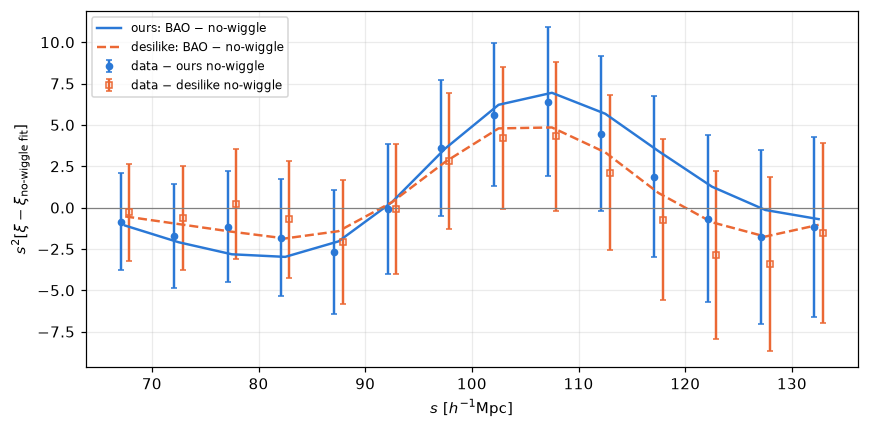

In [8]:
lik_nw, obs_nw = make_likelihood(only_now=True)
_, best_nw, chi2_nw = best_fit(lik_nw)
lik_nw(**best_nw); model_d_nw = np.array(obs_nw.flattheory)

det_d = chi2_nw - chi2_bao - prior_term
print(f"desilike: chi2_BAO = {chi2_bao:.2f} (+ prior term {prior_term:.2f}),  chi2_nowiggle = {chi2_nw:.2f}")
print(f"          Delta chi2_det = {det_d:.2f} (run_all convention),  {chi2_nw - chi2_bao:.2f} (data chi2 only)")
print(f"ours    : chi2_BAO = {ours['chi2_min']:.2f} (prior incl.),  chi2_nowiggle = {ours['chi2_nowiggle']:.2f},  "
      f"Delta chi2_det = {ours['dchi2_wiggle']:.2f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(s[m] - 0.4, s[m]**2 * (xi[m] - m_ours_nw[m]), yerr=s[m]**2 * sig[m], fmt='o', ms=4, capsize=2,
            color=OURS, label='data − ours no-wiggle')
ax.errorbar(s[m] + 0.4, s[m]**2 * (xi[m] - model_d_nw), yerr=s[m]**2 * sig[m], fmt='s', ms=3.5, mfc='none',
            capsize=2, color=DESI, label='data − desilike no-wiggle')
ax.plot(s[m], s[m]**2 * (m_ours[m] - m_ours_nw[m]), color=OURS, label='ours: BAO − no-wiggle')
ax.plot(s[m], s[m]**2 * (model_d - model_d_nw), color=DESI, ls='--', label='desilike: BAO − no-wiggle')
ax.axhline(0, color='0.5', lw=0.8); ax.set_xlabel(r'$s\ [h^{-1}{\rm Mpc}]$')
ax.set_ylabel(r'$s^2[\xi - \xi_{\rm no\text{-}wiggle\ fit}]$'); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## 7. χ²(α) profile

At each α, desilike refits all the other parameters (b1, Σ with its prior, broadband); ours
minimises over its Σ grid with the linear parameters solved exactly. Both curves are relative
to their own minimum; the dotted line is Δχ² = 1 (the 68% interval). Same shape → same α and
same error.

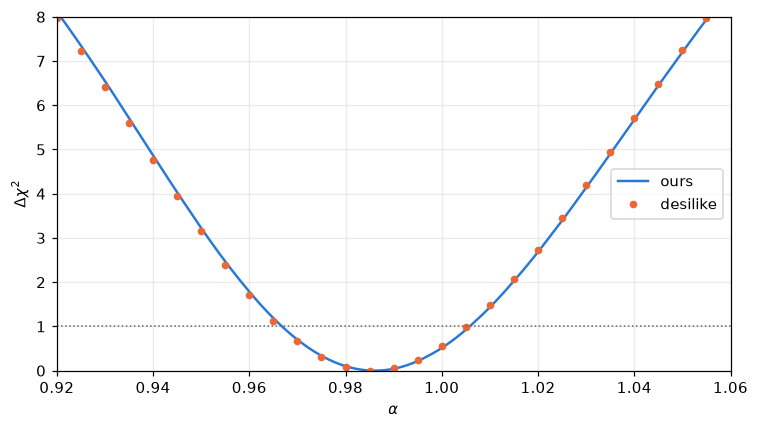

In [9]:
grid = np.linspace(0.92, 1.06, 29)
prof.profile(params=['qiso'], grid=grid)
pr = np.asarray(prof.profiles.profile['qiso'])               # columns: qiso, log posterior
d_chi2_d = -2 * (pr[:, 1] - pr[:, 1].max())
d_chi2_o = ours['prof_alpha'] - ours['prof_alpha'].min()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ours['alpha_grid'], d_chi2_o, color=OURS, label='ours')
ax.plot(pr[:, 0], d_chi2_d, 'o', ms=4, color=DESI, label='desilike')
ax.axhline(1, color='0.4', ls=':', lw=1)
ax.set_xlim(grid[0], grid[-1]); ax.set_ylim(0, 8)
ax.set_xlabel(r'$\alpha$'); ax.set_ylabel(r'$\Delta\chi^2$'); ax.legend(); fig.tight_layout(); plt.show()

## 8. Summary

Profile best fit and Δχ² = 1 interval for α (the `run_all` summary table quotes the marginal
posterior std instead; for these well-behaved posteriors the two are close).

In [10]:
iv = prof.profiles.interval['qiso']
rows = [('alpha', f"{ours['alpha']:.4f} [{ours['lo']:.4f}, {ours['hi']:.4f}]",
                  f"{best['qiso']:.4f} [{best['qiso'] + iv[0]:.4f}, {best['qiso'] + iv[1]:.4f}]"),
        ('Sigma', f"{ours['Sigma']:.2f}", f"{best['sigmaper']:.2f}"),
        ('chi2 / dof (prior incl.)', f"{ours['chi2_min']:.2f} / {ours['dof']}", f"{chi2_bao + prior_term:.2f} / {ours['dof']}"),
        ('chi2 no-wiggle', f"{ours['chi2_nowiggle']:.2f}", f"{chi2_nw:.2f}"),
        ('Delta chi2_det', f"{ours['dchi2_wiggle']:.2f}", f"{det_d:.2f}")]
print(f"{'':<26}{'ours (run_all)':<28}{'desilike':<28}")
for r in rows:
    print(f"{r[0]:<26}{r[1]:<28}{r[2]:<28}")

                          ours (run_all)              desilike                    
alpha                     0.9861 [0.9668, 1.0058]     0.9856 [0.9663, 1.0054]     
Sigma                     6.47                        6.46                        
chi2 / dof (prior incl.)  7.11 / 8                    7.17 / 8                    
chi2 no-wiggle            19.35                       17.77                       
Delta chi2_det            12.24                       10.60                       
